# 09 - The explanation attack: keep the decision, destroy the explanation

**This is the main contribution. It supersedes Part B of `03`, all of `04`, and the
transfer experiment in `05`.**

It completes the third point of the supervisor review - the "after the attack" half of

> * ...include Insertion and Deletion curves for the whole dataset. And then compare them
>   before and after the attack.

and inherits the probe/reference convention that answers the fourth point.

## The threat model in one sentence

A face verification system says *"these two photographs are the same person"* and shows a
saliency map to justify it - *"...because the eyes and the nose bridge match"*. The
adversary adds an imperceptible perturbation to **one** of the two photographs that leaves
the match decision and even the similarity score essentially unchanged, but makes the
saliency map point somewhere misleading. A human reviewer - a border officer, a forensic
expert in court - is handed a plausible-looking decision with a fabricated justification.

## What changes versus notebooks 04 and 05

| | 04 / 05 | Here |
|---|---|---|
| Pairs attacked | 40 (and 20 for transfer) | **all accepted genuine pairs (~3,000)** |
| Decision constraint | one-sided `relu(SIM_FLOOR - sim)` | **two-sided band around the original score** |
| Threshold | 0.30, hand-picked | **EER from notebook 06, plus an FMR table** |
| Explanation evaluation | Pearson correlation of the maps | **insertion/deletion faithfulness before vs after**, plus correlation and top-k IoU |
| xSSAB | `grad x input` stand-in | **implementation of the published algorithm** |

### Why the constraint became two-sided

Notebook 04 constrained the score only from below (`sim >= 0.45`), so the attack was free
to push it *upward*, and a genuine pair starting at 0.73 could end at 0.82. That is not a
bug - the decision was preserved, which was all the constraint asked for - but it reads as
one, and the review flagged exactly that. Here the constraint is

```
pred_loss = relu( |sim - sim_original| - SIM_TOL )
```

plus a hard per-sample projection that shrinks the perturbation whenever the score leaves
the band or drops below the operating threshold. The reported `delta sim` is therefore
centred on zero: the score barely moves in **either** direction, which is a strictly
stronger claim than "the decision was preserved".

### Why the evaluation changed

"Pearson r fell from 1.0 to 0.06" says the map *changed*. It does not say the map became
*wrong* - a map could change and still be faithful. Insertion and deletion answer the
question that matters: after the attack, do the pixels the map highlights still carry the
match? The baseline is notebook 07's measurement on the unattacked images, and the floor
is its random-saliency control.

**The claim this notebook tests:** after the attack, the deletion AUC should *rise* and
the insertion AUC should *fall*, moving toward the random floor, while the decision and
the score stay put.

## Cost

Roughly two hours on a T4 at full scale: about 45 minutes for the attack itself
(second-order gradients) and about an hour for the before/after evaluation across three
explanation methods. Set `MAX_PAIRS` for a smoke test first.

## CONFIG - edit only this cell

In [1]:
import torch

# =================================================================
# PATHS - update to match your Kaggle dataset / model slugs
# =================================================================
IMAGES_DIR   = "/kaggle/input/datasets/xitij27/hcml-lfw-dataset/imgs"
WEIGHTS_PATH = "/kaggle/input/models/xitij27/elastic-face-arc/pytorch/default/1/ElasticFaceArc.pth"
OUTPUT_DIR   = "/kaggle/working/"

# =================================================================
# DATASET LAYOUT  -  the fix for feedback point 1
# =================================================================
# The image directory holds 12,000 files (0.jpg .. 11999.jpg), i.e. 6,000
# pairs, NOT the 900 pairs used in notebooks 01-05.  Consecutive images form
# a pair (0,1), (2,3), ...  The pairs follow the standard LFW view-2 layout:
# 10 folds x 600 pairs, and each fold is 300 genuine pairs followed by 300
# imposter pairs.  Notebook 06 verifies this empirically before use.
N_IMAGES         = 12000
N_PAIRS          = N_IMAGES // 2      # 6000
PAIRS_PER_FOLD   = 600
GENUINE_PER_FOLD = 300
N_FOLDS          = N_PAIRS // PAIRS_PER_FOLD   # 10

# =================================================================
# PROBE / REFERENCE  -  the fix for feedback point 4
# =================================================================
# An attack may modify exactly ONE image of a pair: the "probe".  The other
# image, the "reference", is never touched.  PROBE_SIDE="random" picks the
# side with a seeded per-pair coin flip, so the attacked image is not
# systematically image 0 of every pair while the run stays reproducible.
PROBE_SIDE = "random"        # 0 | 1 | "random"
PROBE_SEED = 20260728

# =================================================================
# MODEL
# =================================================================
NUM_FEATURES = 512
IMG_SIZE     = 112

# =================================================================
# THIS NOTEBOOK
# =================================================================
MAX_PAIRS    = None      # None = every accepted genuine pair (~3,000)
ATTACK_BATCH = 16        # halves automatically on CUDA OOM

# --- attack ---------------------------------------------------------------
EPSILON_255 = 4.0        # budget in grey levels out of 255  (-> 0.0314 in [-1,1])
STEPS_EXPL  = 40
ALPHA_FRAC  = 0.15       # step size as a fraction of epsilon
LAMBDA_PRED = 4.0        # weight on the decision-stability penalty
LAMBDA_EXPL = 1.0        # weight on the explanation term
SIM_TOL     = 0.05       # the score may drift this far in EITHER direction
SHRINK_STEPS = 8         # hard-projection halvings per iteration

# --- explanation methods --------------------------------------------------
ATTACKED_METHOD  = "gradient"      # the map the attack optimises
# All re-measured before vs after.  Both xSSAB variants are included because
# notebook 07 ranked the combined (actor - counteractor) map last of the three
# methods, and the actor map alone is arguably the more natural answer to
# "which pixels support this match".  Measuring both settles it here rather
# than leaving the choice open to challenge.  Costs ~11% extra runtime.
TRANSFER_METHODS = ["gradient", "xssab", "xssab_actor", "xface"]

XSSAB_THR = 0.0
XFACE_GRID          = 14
XFACE_OCC_BATCH     = 196
XFACE_OCCLUDE_VALUE = 0.0
RANDOM_SALIENCY_SEED = 1234

# --- evaluation -----------------------------------------------------------
INSDEL_STEPS      = 20
DELETE_VALUE      = 0.0
INSERT_BLUR_SIGMA = 8.0
TOPK_FRAC         = 0.10
CHECKPOINT_EVERY  = 200

# Pairs shown in the qualitative figures.  These must be GENUINE and ACCEPTED,
# otherwise they are not in the attack set and are silently skipped.  Genuine
# means (pair % 600) < 300.  Verified against notebook 06's scores:
#   0 (+0.73), 1 (+0.84), 3000 (+0.65) - all genuine and well above the threshold.
VIZ_PAIRS = [0, 1, 3000]
assert all((p % 600) < 300 for p in VIZ_PAIRS), "a VIZ pair is not a genuine pair"

# =================================================================
# RUNTIME
# =================================================================
USE_AMP        = True     # fp16 autocast for EVALUATION forward passes only
                          # (never inside an attack loop - see notebook 08/09)
EMBED_BATCH    = 128      # batch size for plain embedding extraction
PRELOAD_IMAGES = True     # cache all 12,000 images in RAM (~450 MB)
N_GPUS         = None     # None = use every visible GPU.  Kaggle's "GPU T4 x2"
                          # exposes two; set to 1 to force single-GPU.

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Primary device : {DEVICE}")
for _i in range(torch.cuda.device_count()):
    _p = torch.cuda.get_device_properties(_i)
    print(f"  cuda:{_i} : {_p.name}  {_p.total_memory / 1e9:.1f} GB")

Primary device : cuda
  cuda:0 : Tesla T4  15.6 GB
  cuda:1 : Tesla T4  15.6 GB


## Imports

In [2]:
import os
import json
import math
import numpy as np
import cv2
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd
from contextlib import nullcontext
from tqdm.auto import tqdm
import warnings
warnings.filterwarnings("ignore")

np.random.seed(0)
torch.manual_seed(0)
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

## Backbone

In [3]:
def conv3x3(in_planes, out_planes, stride=1, groups=1, dilation=1):
    return nn.Conv2d(in_planes, out_planes, kernel_size=3, stride=stride,
                     padding=dilation, groups=groups, bias=False, dilation=dilation)

def conv1x1(in_planes, out_planes, stride=1):
    return nn.Conv2d(in_planes, out_planes, kernel_size=1, stride=stride, bias=False)


class IBasicBlock(nn.Module):
    expansion = 1
    def __init__(self, inplanes, planes, stride=1, downsample=None,
                 groups=1, base_width=64, dilation=1, use_se=False):
        super().__init__()
        self.bn1        = nn.BatchNorm2d(inplanes, eps=1e-05)
        self.conv1      = conv3x3(inplanes, planes)
        self.bn2        = nn.BatchNorm2d(planes, eps=1e-05)
        self.prelu      = nn.PReLU(planes)
        self.conv2      = conv3x3(planes, planes, stride)
        self.bn3        = nn.BatchNorm2d(planes, eps=1e-05)
        self.downsample = downsample
        self.stride     = stride

    def forward(self, x):
        identity = x
        out = self.bn1(x)
        out = self.conv1(out)
        out = self.bn2(out)
        out = self.prelu(out)
        out = self.conv2(out)
        out = self.bn3(out)
        if self.downsample is not None:
            identity = self.downsample(x)
        out += identity
        return out


class IResNet(nn.Module):
    fc_scale = 7 * 7
    def __init__(self, block, layers, dropout=0, num_features=512,
                 groups=1, width_per_group=64,
                 replace_stride_with_dilation=None):
        super().__init__()
        self.inplanes   = 64
        self.dilation   = 1
        if replace_stride_with_dilation is None:
            replace_stride_with_dilation = [False, False, False]
        self.groups     = groups
        self.base_width = width_per_group
        self.conv1      = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1        = nn.BatchNorm2d(64, eps=1e-05)
        self.prelu      = nn.PReLU(64)
        self.layer1     = self._make_layer(block, 64,  layers[0], stride=2)
        self.layer2     = self._make_layer(block, 128, layers[1], stride=2,
                                           dilate=replace_stride_with_dilation[0])
        self.layer3     = self._make_layer(block, 256, layers[2], stride=2,
                                           dilate=replace_stride_with_dilation[1])
        self.layer4     = self._make_layer(block, 512, layers[3], stride=2,
                                           dilate=replace_stride_with_dilation[2])
        self.bn2        = nn.BatchNorm2d(512 * block.expansion, eps=1e-05)
        self.dropout    = nn.Dropout(p=dropout, inplace=True)
        self.fc         = nn.Linear(512 * block.expansion * self.fc_scale, num_features)
        self.features   = nn.BatchNorm1d(num_features, eps=1e-05)
        nn.init.constant_(self.features.weight, 1.0)
        self.features.weight.requires_grad = False
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.normal_(m.weight, 0, 0.1)
            elif isinstance(m, (nn.BatchNorm2d, nn.GroupNorm)):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def _make_layer(self, block, planes, num_blocks, stride=1, dilate=False):
        downsample    = None
        prev_dilation = self.dilation
        if dilate:
            self.dilation *= stride
            stride = 1
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                conv1x1(self.inplanes, planes * block.expansion, stride),
                nn.BatchNorm2d(planes * block.expansion, eps=1e-05),
            )
        layers = [block(self.inplanes, planes, stride, downsample,
                        self.groups, self.base_width, prev_dilation)]
        self.inplanes = planes * block.expansion
        for _ in range(1, num_blocks):
            layers.append(block(self.inplanes, planes, groups=self.groups,
                                base_width=self.base_width, dilation=self.dilation))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.prelu(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.bn2(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        x = self.features(x)
        return x


def elastic_iresnet100(**kwargs):
    return IResNet(IBasicBlock, [3, 13, 30, 3], **kwargs)

## Data, threshold and plotting utilities

In [4]:
# ---------------------------------------------------------------- images ---
def preprocess(img_rgb):
    """(H,W,3) uint8 RGB -> (3,H,W) float32 tensor in [-1, 1]."""
    x = ((img_rgb.astype(np.float32) / 255.0) - 0.5) / 0.5
    return torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1)))


IMAGE_CACHE = None

def _read_image(img_idx):
    path = os.path.join(IMAGES_DIR, f"{img_idx}.jpg")
    bgr = cv2.imread(path)
    if bgr is None:
        raise FileNotFoundError(path)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def preload_images(n=N_IMAGES):
    """Hold every image in RAM so the long loops never re-decode a JPEG."""
    global IMAGE_CACHE
    cache = np.zeros((n, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    for i in tqdm(range(n), desc="Caching images", leave=False):
        cache[i] = _read_image(i)
    IMAGE_CACHE = cache
    print(f"Cached {n:,} images ({cache.nbytes / 1e6:.0f} MB)")


def image_rgb(img_idx):
    return IMAGE_CACHE[img_idx] if IMAGE_CACHE is not None else _read_image(img_idx)


def image_tensor(img_idx):
    return preprocess(image_rgb(img_idx))


def tensor_to_uint8(t):
    """(3,H,W) or (1,3,H,W) float tensor in [-1,1] -> (H,W,3) uint8."""
    x = t.detach().float().cpu().numpy()
    if x.ndim == 4:
        x = x[0]
    x = x.transpose(1, 2, 0)
    return np.clip((x * 0.5 + 0.5) * 255, 0, 255).astype(np.uint8)


# ------------------------------------------------------- pair bookkeeping ---
def _build_probe_sides():
    if PROBE_SIDE in (0, 1):
        return np.full(N_PAIRS, int(PROBE_SIDE), dtype=np.int64)
    if PROBE_SIDE != "random":
        raise ValueError(f"PROBE_SIDE must be 0, 1 or 'random', got {PROBE_SIDE!r}")
    return np.random.RandomState(PROBE_SEED).randint(0, 2, size=N_PAIRS)

PROBE_SIDES = _build_probe_sides()


def probe_reference(pair_idx):
    """(probe_img_idx, reference_img_idx) - always two DIFFERENT image files.

    The probe is the ONLY image any attack in this project is allowed to
    modify; the reference is passed through the model untouched.
    """
    i0, i1 = 2 * int(pair_idx), 2 * int(pair_idx) + 1
    probe, ref = (i0, i1) if PROBE_SIDES[pair_idx] == 0 else (i1, i0)
    assert probe != ref, "probe and reference must be two different images"
    return probe, ref


def is_genuine(pair_idx):
    """LFW view-2: every fold is 300 genuine pairs then 300 imposter pairs."""
    return (np.asarray(pair_idx) % PAIRS_PER_FOLD) < GENUINE_PER_FOLD


def fold_of(pair_idx):
    return np.asarray(pair_idx) // PAIRS_PER_FOLD


PAIR_IDX   = np.arange(N_PAIRS)
IS_GENUINE = is_genuine(PAIR_IDX)
FOLD       = fold_of(PAIR_IDX)
PROBE_IMG  = np.where(PROBE_SIDES == 0, 2 * PAIR_IDX, 2 * PAIR_IDX + 1)
REF_IMG    = np.where(PROBE_SIDES == 0, 2 * PAIR_IDX + 1, 2 * PAIR_IDX)


def load_pair_batch(pair_indices, device=None):
    """-> (probes, references), each (B,3,112,112) on DEVICE."""
    device = device or DEVICE
    probes = torch.stack([image_tensor(int(PROBE_IMG[i])) for i in pair_indices]).to(device)
    refs   = torch.stack([image_tensor(int(REF_IMG[i]))   for i in pair_indices]).to(device)
    return probes, refs


# ----------------------------------------------------------------- model ---
def amp_ctx(device=None):
    dev = DEVICE if device is None else device
    if USE_AMP and dev.type == "cuda":
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    return nullcontext()


def load_model_on(dev):
    m = elastic_iresnet100(num_features=NUM_FEATURES)
    state = torch.load(WEIGHTS_PATH, map_location="cpu")
    if isinstance(state, dict) and "state_dict" in state:
        state = state["state_dict"]
    m.load_state_dict(state)
    m = m.to(dev).eval()
    # We only ever differentiate w.r.t. the INPUT image, never the weights.
    # Freezing the parameters keeps the second-order graphs in notebook 09
    # from also tracking weight gradients.
    for p in m.parameters():
        p.requires_grad_(False)
    return m


def load_model():
    return load_model_on(DEVICE)


@torch.no_grad()
def embed_batch(x):
    """(B,3,H,W) -> (B,D) L2-normalised embeddings (float32)."""
    with amp_ctx(x.device):
        e = current_model()(x)
    return F.normalize(e.float(), dim=1)


@torch.no_grad()
def embed_images(img_indices, batch=None, desc="Embedding"):
    batch = batch or EMBED_BATCH
    img_indices = np.asarray(img_indices)
    out = np.zeros((len(img_indices), NUM_FEATURES), dtype=np.float32)
    for s in tqdm(range(0, len(img_indices), batch), desc=desc, leave=False):
        chunk = img_indices[s:s + batch]
        x = torch.stack([image_tensor(int(i)) for i in chunk]).to(DEVICE)
        out[s:s + len(chunk)] = embed_batch(x).cpu().numpy()
    return out


def compute_all_scores():
    """Embed all 12,000 images and return (embeddings, 6,000 pair scores)."""
    emb = embed_images(np.arange(N_IMAGES), desc="Embedding 12,000 images")
    scores = (emb[0::2] * emb[1::2]).sum(1)   # cosine similarity per pair
    return emb, scores

# =========================================================================
# Multi-GPU execution
# =========================================================================
# Kaggle's "GPU T4 x2" accelerator gives two devices; a single-threaded loop
# uses one and leaves the other idle.  The work in these notebooks is
# embarrassingly parallel across pairs - every pair's saliency map and
# insertion/deletion curve is independent of every other - so it splits
# cleanly: give each GPU its own replica of the model and hand each a
# different chunk of pairs.
#
# Threads, not processes.  CUDA kernel launches release the GIL, so two
# threads driving two devices genuinely overlap, and they share the 452 MB
# image cache rather than duplicating it per process.  Each thread keeps its
# replica in thread-local storage; `current_model()` is what every forward
# pass in this notebook actually calls.
#
# Autocast, no_grad and the autograd graph are all thread-local in PyTorch,
# so the saliency and attack code needs no locking.
import threading
from concurrent.futures import ThreadPoolExecutor

_TLS = threading.local()


def available_devices(limit=None):
    n = torch.cuda.device_count()
    if n == 0:
        return [torch.device("cpu")]
    return [torch.device(f"cuda:{i}") for i in range(n if limit is None else min(n, limit))]


DEVICES = available_devices(N_GPUS)


def current_model():
    """The model replica belonging to the calling thread."""
    m = getattr(_TLS, "model", None)
    return MODELS[DEVICES[0]] if m is None else m


def parallel_chunks(chunk_list, worker, desc=""):
    """Run worker(i, chunk, device) over chunk_list, one thread per GPU.

    Yields results in submission order, so downstream code can rely on the
    ordering while the GPUs run out of order underneath.
    """
    if len(DEVICES) == 1:
        _TLS.model = MODELS[DEVICES[0]]
        for i, ch in enumerate(tqdm(chunk_list, desc=desc)):
            yield worker(i, ch, DEVICES[0])
        return

    def run(i, ch):
        dev = DEVICES[i % len(DEVICES)]
        _TLS.model = MODELS[dev]
        with torch.cuda.device(dev):
            return worker(i, ch, dev)

    with ThreadPoolExecutor(max_workers=len(DEVICES)) as ex:
        futures = [ex.submit(run, i, ch) for i, ch in enumerate(chunk_list)]
        for f in tqdm(futures, desc=f"{desc} [{len(DEVICES)} GPUs]"):
            yield f.result()


def chunk_offsets(chunk_list):
    """Start index of each chunk in the flattened pair ordering."""
    return np.concatenate([[0], np.cumsum([len(c) for c in chunk_list])]).astype(int)

# ------------------------------------------------- FMR / FNMR / EER tools ---
# FMR  (False Match Rate)     = fraction of IMPOSTER pairs scoring >= threshold
# FNMR (False Non-Match Rate) = fraction of GENUINE  pairs scoring <  threshold
# Both are computed exactly by binary search on the sorted score arrays - no
# histogram binning, no interpolation.

def fmr_at(imposter_sorted, t):
    n = len(imposter_sorted)
    return 1.0 - np.searchsorted(imposter_sorted, t, side="left") / n


def fnmr_at(genuine_sorted, t):
    n = len(genuine_sorted)
    return np.searchsorted(genuine_sorted, t, side="left") / n


def candidate_thresholds(genuine_sorted, imposter_sorted):
    """Every score, and every score nudged up by one ulp: the complete set of
    operating points at which FMR/FNMR can change."""
    c = np.unique(np.concatenate([genuine_sorted, imposter_sorted]))
    c = np.unique(np.concatenate([c, np.nextafter(c, np.inf)]))
    return c


def compute_eer(genuine_sorted, imposter_sorted):
    """Exact EER and the threshold that achieves it."""
    c = candidate_thresholds(genuine_sorted, imposter_sorted)
    fmr, fnmr = fmr_at(imposter_sorted, c), fnmr_at(genuine_sorted, c)
    k = int(np.argmin(np.abs(fmr - fnmr)))
    return float(c[k]), float((fmr[k] + fnmr[k]) / 2.0)


def threshold_at_fmr(imposter_sorted, target_fmr):
    """Lowest threshold whose FMR is <= target_fmr."""
    n = len(imposter_sorted)
    k = int(np.floor(target_fmr * n))            # imposters we are allowed to accept
    if k >= n:
        return float(imposter_sorted[0])
    return float(np.nextafter(imposter_sorted[n - 1 - k], np.inf))


def operating_point(scores, genuine_mask, t):
    """(FMR, FNMR, accuracy) of threshold t on a set of scores."""
    g = scores[genuine_mask]
    i = scores[~genuine_mask]
    fmr  = float((i >= t).mean())
    fnmr = float((g <  t).mean())
    acc  = float(((g >= t).sum() + (i < t).sum()) / len(scores))
    return fmr, fnmr, acc

# --------------------------------------------------------------- display ---
def overlay(img_tensor, sal_np, alpha=0.5):
    """Blend a [0,1] saliency map over the image as a JET heatmap."""
    raw = tensor_to_uint8(img_tensor)
    hm = cv2.applyColorMap((np.clip(sal_np, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_JET)
    hm = cv2.cvtColor(hm, cv2.COLOR_BGR2RGB)
    return np.clip(alpha * hm + (1 - alpha) * raw, 0, 255).astype(np.uint8)


def to01(m):
    m = np.asarray(m, dtype=np.float64)
    return (m - m.min()) / (m.max() - m.min() + 1e-8)


def save_fig(name, dpi=140):
    path = os.path.join(OUTPUT_DIR, name)
    plt.savefig(path, dpi=dpi, bbox_inches="tight")
    print("saved", path)

# ------------------------------------------------------------ checkpoints ---
# Kaggle sessions die; long loops should not lose their work when they do.
# Tracks the last saved row count rather than testing `len(rows) % every == 0`,
# which only fires when the batch size happens to divide `every`.
_CKPT_SAVED = {}

def checkpoint_rows(rows, filename, every=None, force=False):
    every = CHECKPOINT_EVERY if every is None else every
    if force or len(rows) - _CKPT_SAVED.get(filename, 0) >= every:
        pd.DataFrame(rows).to_csv(os.path.join(OUTPUT_DIR, filename), index=False)
        _CKPT_SAVED[filename] = len(rows)
    return rows

def batches(seq, size):
    """Yield consecutive slices of an index array."""
    seq = np.asarray(seq)
    for s in range(0, len(seq), size):
        yield seq[s:s + size]

## Explanation methods and faithfulness metrics

Identical to notebook 07, so the before/after numbers are measured on exactly the same footing.

In [5]:
# =========================================================================
# Explanation methods.  All take (probes, ref_emb) and return (B,H,W) maps
# where a HIGHER value means "this pixel matters more for the match".
# =========================================================================

def saliency_gradient(probes, ref_emb, create_graph=False):
    """Squared input-gradient:  mean_c ( d cos / d probe )^2.

    Cheap, fully differentiable, and the map the explanation attack in
    notebook 09 optimises against.
    """
    x = probes if probes.requires_grad else probes.clone().requires_grad_(True)
    sim = (F.normalize(current_model()(x), dim=1) * ref_emb).sum(1)
    g = torch.autograd.grad(sim.sum(), x, create_graph=create_graph)[0]
    return g.pow(2).mean(1)


def saliency_xssab(probes, ref_emb, thr=None, create_graph=False):
    """xSSAB - Similarity Score Argument Backpropagation.

    Our implementation of the method published in
      M. Huber et al., "Efficient Explainable Face Verification based on
      Similarity Score Argument Backpropagation", WACV 2024.
      https://arxiv.org/abs/2304.13409 - https://github.com/marcohuber/xSSAB
    (Written from the paper and the reference implementation's documented
    behaviour; the official repository carries no licence, so no code from it
    is redistributed here.)

    For L2-normalised embeddings the similarity decomposes exactly into a sum
    of per-dimension arguments:

        cos(e_probe, e_ref) = sum_d  e_probe[d] * e_ref[d]

    Dimensions whose argument is >= thr/D SUPPORT the match ("actor"); the
    rest OPPOSE it ("counteractor").  Each partial score is back-propagated
    separately, to the PROBE image only, and reduced over colour channels as
    the mean absolute gradient.

    Returns (actor, counteractor, combined) with combined = actor - counteractor.
    """
    thr = XSSAB_THR if thr is None else thr
    x = probes if probes.requires_grad else probes.clone().requires_grad_(True)
    e = F.normalize(current_model()(x), dim=1)
    arg = e * ref_emb                       # (B,D);  arg.sum(1) == cosine
    t = thr / arg.shape[1]
    support = (arg.detach() >= t).float()

    s_pos = (arg * support).sum(1)
    s_neg = (arg * (1.0 - support)).sum(1)
    g_pos = torch.autograd.grad(s_pos.sum(), x, create_graph=create_graph,
                                retain_graph=True)[0]
    g_neg = torch.autograd.grad(s_neg.sum(), x, create_graph=create_graph)[0]

    actor        = g_pos.abs().mean(1)
    counteractor = g_neg.abs().mean(1)
    return actor, counteractor, actor - counteractor


@torch.no_grad()
def saliency_xface(probes, ref_emb, grid=None, occ_batch=None):
    """xFace-style occlusion: black out one grid cell at a time and record how
    far the similarity drops.  Gradient-free, so it is the honest control for
    whether an attack changed the model's behaviour or only tickled its
    gradient.  Costs grid^2 forward passes per map.
    """
    grid = XFACE_GRID if grid is None else grid
    occ_batch = XFACE_OCC_BATCH if occ_batch is None else occ_batch
    B, C, H, W = probes.shape
    ch, cw = H // grid, W // grid
    base = (embed_batch(probes) * ref_emb).sum(1)              # (B,)
    cells = [(i, j) for i in range(grid) for j in range(grid)]
    sal = torch.zeros(B, H, W, device=probes.device)
    for b in range(B):
        drops = torch.zeros(len(cells), device=probes.device)
        for s in range(0, len(cells), occ_batch):
            chunk = cells[s:s + occ_batch]
            xb = probes[b:b + 1].repeat(len(chunk), 1, 1, 1)
            for k, (i, j) in enumerate(chunk):
                xb[k, :, i * ch:(i + 1) * ch, j * cw:(j + 1) * cw] = XFACE_OCCLUDE_VALUE
            e = embed_batch(xb)
            drops[s:s + len(chunk)] = base[b] - (e * ref_emb[b:b + 1]).sum(1)
        for k, (i, j) in enumerate(cells):
            sal[b, i * ch:(i + 1) * ch, j * cw:(j + 1) * cw] = drops[k]
    return sal.clamp(min=0)


def saliency_random(probes, pair_indices):
    """Uniform noise - the control that fixes the SCALE of every faithfulness
    number.  Whatever insertion/deletion AUC this reaches is what 'no
    explanation at all' scores on this model and dataset."""
    maps = np.stack([
        np.random.RandomState((RANDOM_SALIENCY_SEED + int(p)) % (2 ** 32)).rand(IMG_SIZE, IMG_SIZE)
        for p in pair_indices
    ]).astype(np.float32)
    return torch.from_numpy(maps).to(probes.device)


def compute_saliency(method, probes, ref_emb, pair_indices):
    """Dispatch by name.  Returns a detached (B,H,W) float32 tensor."""
    if method == "gradient":
        m = saliency_gradient(probes, ref_emb)
    elif method == "xssab":
        m = saliency_xssab(probes, ref_emb)[2]
    elif method == "xssab_actor":
        m = saliency_xssab(probes, ref_emb)[0]
    elif method == "xface":
        m = saliency_xface(probes, ref_emb)
    elif method == "random":
        m = saliency_random(probes, pair_indices)
    else:
        raise ValueError(f"unknown explanation method {method!r}")
    return m.detach().float()


def normalize01(m):
    """Min-max to [0,1] per sample - for DISPLAY only.  Never applied before
    insertion/deletion, which only needs the pixel ranking."""
    flat = m.reshape(m.shape[0], -1) if m.ndim == 3 else m.reshape(1, -1)
    lo = flat.min(1, keepdim=True)[0]
    hi = flat.max(1, keepdim=True)[0]
    out = (flat - lo) / (hi - lo + 1e-8)
    return out.reshape(m.shape)

In [6]:
# =========================================================================
# Insertion / Deletion faithfulness curves  -  feedback point 3
# =========================================================================

def gaussian_blur(x, sigma):
    """Separable Gaussian blur for (B,C,H,W)."""
    r = max(1, int(round(3 * sigma)))
    t = torch.arange(-r, r + 1, device=x.device, dtype=torch.float32)
    k = torch.exp(-t.pow(2) / (2.0 * sigma * sigma))
    k = k / k.sum()
    C = x.shape[1]
    kh = k.view(1, 1, 1, -1).expand(C, 1, 1, -1)
    kv = k.view(1, 1, -1, 1).expand(C, 1, -1, 1)
    x = F.conv2d(F.pad(x, (r, r, 0, 0), mode="reflect"), kh, groups=C)
    x = F.conv2d(F.pad(x, (0, 0, r, r), mode="reflect"), kv, groups=C)
    return x


@torch.no_grad()
def insertion_deletion(probes, ref_emb, sal, steps=None):
    """RISE-style faithfulness curves, adapted to face VERIFICATION.

    The quantity plotted is the cosine similarity to the (untouched)
    reference image, as pixels of the probe are removed or restored in
    saliency order.

      deletion  : start from the probe, progressively REPLACE the most
                  salient pixels with mid-grey.  A faithful map destroys the
                  match early, so a LOW deletion AUC is GOOD.
      insertion : start from a blurred probe, progressively RESTORE the most
                  salient pixels.  A faithful map recovers the match early,
                  so a HIGH insertion AUC is GOOD.

    probes (B,3,H,W) | ref_emb (B,D) L2-normalised | sal (B,H,W)
    returns (deletion_curve, insertion_curve), each (B, steps+1).
    """
    steps = INSDEL_STEPS if steps is None else steps
    B, C, H, W = probes.shape
    N = H * W

    # rank[b, p] = position of pixel p in descending saliency order
    order = torch.argsort(sal.reshape(B, N), dim=1, descending=True)
    rank = torch.empty_like(order)
    positions = torch.arange(N, device=probes.device).expand(B, N).contiguous()
    rank.scatter_(1, order, positions)
    rank = rank.view(B, 1, H, W)

    grey = torch.full_like(probes, DELETE_VALUE)
    blur = gaussian_blur(probes, INSERT_BLUR_SIGMA)

    cuts = np.linspace(0, N, steps + 1).round().astype(int)
    dcur = np.zeros((B, steps + 1), np.float32)
    icur = np.zeros((B, steps + 1), np.float32)
    for si, k in enumerate(cuts):
        m = (rank < int(k)).float()
        ed = embed_batch(probes * (1 - m) + grey * m)
        ei = embed_batch(blur * (1 - m) + probes * m)
        dcur[:, si] = (ed * ref_emb).sum(1).cpu().numpy()
        icur[:, si] = (ei * ref_emb).sum(1).cpu().numpy()
    return dcur, icur


def curve_auc(curve):
    """Trapezoidal area under a curve sampled uniformly on [0, 1]."""
    c = np.asarray(curve, dtype=np.float64)
    n = c.shape[-1]
    w = np.full(n, 1.0 / (n - 1))
    w[0] *= 0.5
    w[-1] *= 0.5
    return (c * w).sum(-1)

# ------------------------------------------- saliency-map change metrics ---
def pearson_maps(a, b):
    """Per-sample Pearson r between two (B,H,W) numpy map stacks."""
    a = np.asarray(a, dtype=np.float64).reshape(len(a), -1)
    b = np.asarray(b, dtype=np.float64).reshape(len(b), -1)
    a = a - a.mean(1, keepdims=True)
    b = b - b.mean(1, keepdims=True)
    den = np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1) + 1e-12
    return (a * b).sum(1) / den


def topk_iou(a, b, frac=None):
    """Overlap of the top-frac most salient pixels before vs after.  A human
    reviewer mostly looks at the brightest region, so this asks whether the
    hot-spot is still in the same place."""
    frac = TOPK_FRAC if frac is None else frac
    a = np.asarray(a).reshape(len(a), -1)
    b = np.asarray(b).reshape(len(b), -1)
    k = max(1, int(a.shape[1] * frac))
    ia = np.argsort(a, axis=1)[:, -k:]
    ib = np.argsort(b, axis=1)[:, -k:]
    out = np.zeros(len(a))
    for i in range(len(a)):
        inter = len(np.intersect1d(ia[i], ib[i], assume_unique=True))
        out[i] = inter / (2 * k - inter)
    return out

## Load model, cache images, recompute the protocol

Note on precision: `USE_AMP` speeds up the insertion/deletion forward passes, but every
**reported** similarity and every decision constraint inside the attack uses the explicit
fp32 path below, so no conclusion depends on half-precision arithmetic.

In [7]:
# One replica per GPU.  `model` stays the primary replica so the plotting and
# single-pair helpers below work unchanged in the main thread; the worker
# threads pick up their own replica via current_model().
MODELS = {d: load_model_on(d) for d in DEVICES}
model = MODELS[DEVICES[0]]
_TLS.model = model
print(f"ElasticFace-Arc loaded on {len(DEVICES)} device(s): "
      f"{', '.join(str(d) for d in DEVICES)}")
print(f"  {sum(p.numel() for p in model.parameters()):,} parameters per replica")

if PRELOAD_IMAGES:
    preload_images()

emb, scores = compute_all_scores()
gen_sorted = np.sort(scores[IS_GENUINE])
imp_sorted = np.sort(scores[~IS_GENUINE])

TAU_EER, EER = compute_eer(gen_sorted, imp_sorted)
THRESHOLDS = {"EER": TAU_EER}
for target in [1e-1, 1e-2, 1e-3]:
    THRESHOLDS[f"FMR<={target:g}"] = threshold_at_fmr(imp_sorted, target)
print(f"EER = {EER:.3%} at threshold {TAU_EER:.4f}")


@torch.no_grad()
def ref_embedding(refs):
    """fp32 L2-normalised embedding of the untouched reference image."""
    return F.normalize(current_model()(refs).float(), dim=1)


@torch.no_grad()
def cos_to_ref(x, ref_emb):
    """fp32 cosine similarity - used for every reported number and for the
    decision constraint inside the attack."""
    return (F.normalize(current_model()(x).float(), dim=1) * ref_emb).sum(1)

# Every image belongs to exactly one pair, so 12,000 images == 6,000 pairs and
# nothing is left unused.  Asserted rather than asserted-in-prose because
# "6,000" next to "12,000 images" reads like half the data is being skipped.
_used = np.unique(np.concatenate([PROBE_IMG, REF_IMG]))
assert len(_used) == N_IMAGES, "probe+reference must cover every image exactly once"

print("Environment ready.")
print(f"  images used     : {len(_used):,} / {N_IMAGES:,}  (each image is in exactly one pair)")
print(f"  pairs           : {N_PAIRS:,} = {N_IMAGES:,} images / 2  "
      f"({int(IS_GENUINE.sum()):,} genuine / {int((~IS_GENUINE).sum()):,} imposter) "
      f"in {N_FOLDS} folds")
print(f"  probe selection : PROBE_SIDE={PROBE_SIDE!r}  seed={PROBE_SEED}  "
      f"(1 image attacked per pair, 1 left untouched)")

ElasticFace-Arc loaded on 2 device(s): cuda:0, cuda:1
  65,156,160 parameters per replica


Caching images:   0%|          | 0/12000 [00:00<?, ?it/s]

Cached 12,000 images (452 MB)


Embedding 12,000 images:   0%|          | 0/94 [00:00<?, ?it/s]

EER = 0.300% at threshold 0.2136
Environment ready.
  images used     : 12,000 / 12,000  (each image is in exactly one pair)
  pairs           : 6,000 = 12,000 images / 2  (3,000 genuine / 3,000 imposter) in 10 folds
  probe selection : PROBE_SIDE='random'  seed=20260728  (1 image attacked per pair, 1 left untouched)


## The attack set

Accepted genuine pairs only: pairs the system calls a match at the EER threshold. The
threat model does not apply anywhere else. An imposter pair scores near zero, so there is
no "why do these match?" explanation to corrupt (notebook 07 shows the faithfulness
metric is degenerate there), and a rejected genuine pair produces no match to justify.

In [8]:
accepted_genuine = PAIR_IDX[IS_GENUINE & (scores >= TAU_EER)]
if MAX_PAIRS is not None:
    accepted_genuine = accepted_genuine[:MAX_PAIRS]

print(f"genuine pairs              : {int(IS_GENUINE.sum()):,}")
print(f"  accepted at EER threshold: {int((IS_GENUINE & (scores >= TAU_EER)).sum()):,}")
print(f"  attacked in this run     : {len(accepted_genuine):,}")
print(f"mean similarity of the attack set: {scores[accepted_genuine].mean():+.4f}")
assert (IS_GENUINE[accepted_genuine]).all()
assert (PROBE_IMG[accepted_genuine] != REF_IMG[accepted_genuine]).all(), \
    "probe and reference must always be two different images"

genuine pairs              : 3,000
  accepted at EER threshold: 2,991
  attacked in this run     : 2,991
mean similarity of the attack set: +0.7215


## The attack

A tug-of-war written as one loss to **minimise**, one gradient-descent step per
iteration - no sign hidden anywhere:

```
L  =  LAMBDA_PRED * relu( |sim - sim_0| - SIM_TOL )     keep the score where it was
   +  LAMBDA_EXPL * pearson( map_attacked , map_original )    move the explanation
```

* The **decision term** is zero while the score stays inside its band, so the attack has
  free rein until it starts to disturb the match.
* The **explanation term** is Pearson correlation, which is scale invariant. This matters:
  notebook 03 maximised MSE between the maps but *reported* correlation, which is why its
  correlation barely moved. Doubling every value of a map produces a large MSE and leaves
  the correlation at 1.0 - the same pixels still light up, so a reviewer sees the same
  picture. Correlation cannot be fooled by rescaling; to lower it the hot-spots must
  actually move.

After each step the perturbation is projected back into the epsilon-ball, and then a hard
per-sample projection halves it (up to `SHRINK_STEPS` times) for any sample whose score
has left the band or fallen below the operating threshold. The returned image is therefore
always a confident match with an essentially unchanged score.

One forward pass per iteration serves both terms: the similarity feeds the decision
penalty, and its input-gradient - retained with `create_graph=True` - is the saliency map
the explanation term differentiates through.

In [9]:
# Diagnostic for the hard projection.  The two-sided band is the tightest knob
# in this notebook: if it fires on every step the perturbation is halved away
# faster than the explanation term can move the map, and the attack quietly
# does nothing.  Counting the halvings makes that failure mode visible instead
# of leaving it to be inferred from a disappointing correlation.
ATTACK_STATS = {"sample_steps": 0, "halvings": 0, "hit_cap": 0}
ATTACK_STATS_LOCK = threading.Lock()


def pearson_torch(a, b):
    """Per-sample Pearson correlation between two (B,H,W) tensors."""
    a = a.flatten(1)
    b = b.flatten(1)
    a = a - a.mean(1, keepdim=True)
    b = b - b.mean(1, keepdim=True)
    return (a * b).sum(1) / (a.norm(dim=1) * b.norm(dim=1) + 1e-8)


def explanation_attack(probes, ref_emb, tau,
                       eps=None, alpha=None, steps=None,
                       lambda_pred=None, lambda_expl=None, sim_tol=None):
    eps = EPSILON_255 / 127.5 if eps is None else eps
    alpha = ALPHA_FRAC * eps if alpha is None else alpha
    steps = STEPS_EXPL if steps is None else steps
    lambda_pred = LAMBDA_PRED if lambda_pred is None else lambda_pred
    lambda_expl = LAMBDA_EXPL if lambda_expl is None else lambda_expl
    sim_tol = SIM_TOL if sim_tol is None else sim_tol

    sim0 = cos_to_ref(probes, ref_emb)                      # (B,) fp32

    # the explanation the reviewer would have seen, frozen
    x0 = probes.clone().requires_grad_(True)
    orig_map = saliency_gradient(x0, ref_emb, create_graph=False).detach()

    adv = probes.clone().detach()
    for _ in range(steps):
        adv.requires_grad_(True)

        sim = (F.normalize(current_model()(adv), dim=1) * ref_emb).sum(1)
        # the input-gradient of the SAME forward pass is the saliency map
        g_in = torch.autograd.grad(sim.sum(), adv, create_graph=True)[0]
        att_map = g_in.pow(2).mean(1)

        pred_loss = F.relu((sim - sim0).abs() - sim_tol)
        expl_loss = pearson_torch(att_map, orig_map)
        loss = (lambda_pred * pred_loss + lambda_expl * expl_loss).sum()

        grad = torch.autograd.grad(loss, adv)[0]

        with torch.no_grad():
            adv = adv - alpha * grad.sign()                       # DESCENT
            delta = (adv - probes).clamp(-eps, eps)               # epsilon-ball
            adv = (probes + delta).clamp(-1, 1)

            # hard constraint: shrink the perturbation of any sample whose score
            # left the band or fell below the operating threshold
            n_halvings = torch.zeros(len(probes), device=probes.device)
            for _ in range(SHRINK_STEPS):
                s = cos_to_ref(adv, ref_emb)
                bad = ((s - sim0).abs() > sim_tol) | (s < tau)
                if not bool(bad.any()):
                    break
                n_halvings += bad.float()
                delta = torch.where(bad.view(-1, 1, 1, 1), delta * 0.5, delta)
                adv = (probes + delta).clamp(-1, 1)
            with ATTACK_STATS_LOCK:
                ATTACK_STATS["sample_steps"] += len(probes)
                ATTACK_STATS["halvings"] += float(n_halvings.sum())
                ATTACK_STATS["hit_cap"] += float((n_halvings >= SHRINK_STEPS).sum())
        adv = adv.detach()
    return adv


def attack_with_oom_retry(chunk, tau, min_size=2, device=None):
    """Second-order graphs are memory hungry and the T4 ceiling depends on what
    else Kaggle has resident, so back off by halving rather than guessing."""
    device = DEVICE if device is None else device
    probes, refs = load_pair_batch(chunk, device=device)
    ref_emb = ref_embedding(refs)
    try:
        return probes, refs, ref_emb, explanation_attack(probes, ref_emb, tau)
    except torch.cuda.OutOfMemoryError:
        del probes, refs, ref_emb
        torch.cuda.empty_cache()
        if len(chunk) <= min_size:
            raise
        h = len(chunk) // 2
        pa, ra, ea, aa = attack_with_oom_retry(chunk[:h], tau, min_size, device)
        pb, rb, eb, ab = attack_with_oom_retry(chunk[h:], tau, min_size, device)
        return (torch.cat([pa, pb]), torch.cat([ra, rb]),
                torch.cat([ea, eb]), torch.cat([aa, ab]))

## Run: attack, then re-measure everything

For every batch: craft the adversarial probe, then recompute - for each of the three
explanation methods - the map before and after, their correlation and top-k overlap, and
the full insertion and deletion curves on both.

The "before" curves are recomputed here rather than read from notebook 07 so that both
halves of the comparison are measured on exactly the same pairs, in the same session,
with the same random seeds.

In [10]:
import time

pairs = accepted_genuine
eps = EPSILON_255 / 127.5
chunk_list = list(batches(pairs, ATTACK_BATCH))
offsets = chunk_offsets(chunk_list)
print(f"{len(pairs):,} pairs | eps = {EPSILON_255:g}/255 ({eps:.4f}) | "
      f"{STEPS_EXPL} steps | methods: {', '.join(TRANSFER_METHODS)}")
print(f"{len(chunk_list)} chunks of {ATTACK_BATCH} across {len(DEVICES)} GPU(s)")

rows = []
curve_store = {m: {k: np.zeros((len(pairs), INSDEL_STEPS + 1), np.float32)
                   for k in ("del_before", "ins_before", "del_after", "ins_after")}
               for m in TRANSFER_METHODS}


def attack_chunk(i, chunk, dev):
    """Attack one chunk on one GPU, then re-measure every explanation method
    before and after.  Runs in a worker thread; the second-order graph, the
    autocast state and the model replica are all thread-local."""
    probes, refs, ref_emb, adv = attack_with_oom_retry(chunk, TAU_EER, device=dev)

    sim0 = cos_to_ref(probes, ref_emb).cpu().numpy()
    sim1 = cos_to_ref(adv, ref_emb).cpu().numpy()
    d = (adv - probes)
    linf = (d.abs().amax(dim=(1, 2, 3)) * 127.5).cpu().numpy()
    l2 = d.flatten(1).norm(dim=1).cpu().numpy()

    batch_rows = [dict(pair_idx=int(p), fold=int(FOLD[p]),
                       probe_img=int(PROBE_IMG[p]), ref_img=int(REF_IMG[p]),
                       sim_orig=float(sim0[k]), sim_adv=float(sim1[k]),
                       delta_sim=float(sim1[k] - sim0[k]),
                       linf_255=float(linf[k]), l2=float(l2[k]),
                       **{f"preserved_{n}": bool((sim0[k] >= t) == (sim1[k] >= t))
                          for n, t in THRESHOLDS.items()})
                  for k, p in enumerate(chunk)]

    chunk_curves = {}
    for m in TRANSFER_METHODS:
        map_before = compute_saliency(m, probes, ref_emb, chunk)
        map_after = compute_saliency(m, adv, ref_emb, chunk)
        mb = map_before.cpu().numpy()
        ma = map_after.cpu().numpy()

        r = pearson_maps(mb, ma)
        iou = topk_iou(mb, ma)

        db, ib = insertion_deletion(probes, ref_emb, map_before)
        da, ia = insertion_deletion(adv, ref_emb, map_after)
        chunk_curves[m] = (db, ib, da, ia)

        for k, row in enumerate(batch_rows):
            row[f"{m}_pearson"] = float(r[k])
            row[f"{m}_topk_iou"] = float(iou[k])
            row[f"{m}_del_auc_before"] = float(curve_auc(db[k]))
            row[f"{m}_ins_auc_before"] = float(curve_auc(ib[k]))
            row[f"{m}_del_auc_after"] = float(curve_auc(da[k]))
            row[f"{m}_ins_auc_after"] = float(curve_auc(ia[k]))
    return i, batch_rows, chunk_curves


t0 = time.time()
for i, batch_rows, chunk_curves in parallel_chunks(chunk_list, attack_chunk, desc="Explanation attack"):
    s = offsets[i]
    for m, (db, ib, da, ia) in chunk_curves.items():
        n = len(db)
        curve_store[m]["del_before"][s:s + n] = db
        curve_store[m]["ins_before"][s:s + n] = ib
        curve_store[m]["del_after"][s:s + n] = da
        curve_store[m]["ins_after"][s:s + n] = ia
    rows.extend(batch_rows)
    checkpoint_rows(rows, "explanation_attack.csv")

print(f"attack + evaluation took {(time.time() - t0) / 60:.1f} min")
rows = sorted(rows, key=lambda r: r["pair_idx"])
edf = pd.DataFrame(rows)
edf.to_csv(os.path.join(OUTPUT_DIR, "explanation_attack.csv"), index=False)
print(f"done - {len(edf):,} pairs")

# --- is the decision constraint strangling the attack? --------------------
ss = max(1, ATTACK_STATS["sample_steps"])
per_step = ATTACK_STATS["halvings"] / ss
cap_rate = ATTACK_STATS["hit_cap"] / ss
print(f"\nhard projection: {per_step:.2f} halvings per sample-step, "
      f"cap hit on {cap_rate:.2%} of sample-steps")
if cap_rate > 0.10:
    print("  WARNING: the score band is binding hard. The perturbation is being halved "
          "away faster\n  than the explanation term can move the map, so the attack is "
          "likely under-powered.\n  Raise SIM_TOL (0.05 -> 0.10) or LAMBDA_PRED, then re-run.")
elif per_step < 0.05:
    print("  The band is barely binding - there is room to tighten SIM_TOL if you want a "
          "stronger\n  'the score did not move' claim.")
else:
    print("  Healthy: the constraint engages without dominating.")

2,991 pairs | eps = 4/255 (0.0314) | 40 steps | methods: gradient, xssab, xssab_actor, xface
187 chunks of 16 across 2 GPU(s)


Explanation attack [2 GPUs]:   0%|          | 0/187 [00:00<?, ?it/s]

attack + evaluation took 105.3 min
done - 2,991 pairs

hard projection: 0.31 halvings per sample-step, cap hit on 0.00% of sample-steps
  Healthy: the constraint engages without dominating.


## Result 1 - the decision and the score are untouched

The first thing to establish is that this is an attack on the explanation and nothing
else. `delta sim` should sit in a tight band around zero - not merely on the correct side
of a threshold - and the decision should be preserved at every operating point, not just
the one the attack was tuned against.

In [11]:
print(f"perturbation : mean Linf = {edf.linf_255.mean():.2f}/255 "
      f"(budget {EPSILON_255:g}/255), mean L2 = {edf.l2.mean():.3f}")
print(f"score        : {edf.sim_orig.mean():+.4f} -> {edf.sim_adv.mean():+.4f}"
      f"   mean delta = {edf.delta_sim.mean():+.4f}"
      f"   mean |delta| = {edf.delta_sim.abs().mean():.4f}")
print(f"               95% of pairs move by less than "
      f"{edf.delta_sim.abs().quantile(0.95):.4f}  (SIM_TOL = {SIM_TOL})")
print()
print(f"{'operating point':>16} {'threshold':>10} {'decision preserved':>19}")
print("-" * 48)
for name, t in THRESHOLDS.items():
    print(f"{name:>16} {t:>10.4f} {edf[f'preserved_{name}'].mean():>19.2%}")

perturbation : mean Linf = 2.67/255 (budget 4/255), mean L2 = 2.551
score        : +0.7215 -> +0.7326   mean delta = +0.0110   mean |delta| = 0.0261
               95% of pairs move by less than 0.0474  (SIM_TOL = 0.05)

 operating point  threshold  decision preserved
------------------------------------------------
             EER     0.2136             100.00%
        FMR<=0.1     0.0942             100.00%
       FMR<=0.01     0.1684             100.00%
      FMR<=0.001     0.2484             100.00%


## Result 2 - the explanation is no longer faithful

The headline. For each method: the correlation and top-k overlap say the map *changed*;
the insertion and deletion AUCs say whether it is still *right*.

Read the AUC columns as movement toward the random floor from notebook 07 - deletion AUC
rising and insertion AUC falling both mean the map has lost its grip on the pixels that
actually carry the match.

In [12]:
summary = []
print(f"{'method':>10} {'pearson r':>10} {'top-10% IoU':>12} "
      f"{'deletion AUC':>22} {'insertion AUC':>22}")
print(f"{'':>10} {'(1=same)':>10} {'(1=same)':>12} "
      f"{'before -> after':>22} {'before -> after':>22}")
print("-" * 82)
for m in TRANSFER_METHODS:
    db, da = edf[f"{m}_del_auc_before"].mean(), edf[f"{m}_del_auc_after"].mean()
    ib, ia = edf[f"{m}_ins_auc_before"].mean(), edf[f"{m}_ins_auc_after"].mean()
    r, iou = edf[f"{m}_pearson"].mean(), edf[f"{m}_topk_iou"].mean()
    summary.append(dict(method=m, pearson=r, topk_iou=iou,
                        del_auc_before=db, del_auc_after=da, del_auc_change=da - db,
                        ins_auc_before=ib, ins_auc_after=ia, ins_auc_change=ia - ib,
                        gap_before=ib - db, gap_after=ia - da))
    print(f"{m:>10} {r:>10.3f} {iou:>12.3f} "
          f"{db:>9.3f} -> {da:<9.3f} {ib:>9.3f} -> {ia:<9.3f}")

sdf = pd.DataFrame(summary)
sdf.to_csv(os.path.join(OUTPUT_DIR, "explanation_attack_summary.csv"), index=False)

print()
print("faithfulness gap (insertion AUC - deletion AUC; higher = more faithful)")
for _, r in sdf.iterrows():
    drop = (r.gap_before - r.gap_after) / abs(r.gap_before) * 100 if r.gap_before else float("nan")
    print(f"  {r.method:>10}: {r.gap_before:+.4f} -> {r.gap_after:+.4f}   ({drop:+.1f}%)")

    method  pearson r  top-10% IoU           deletion AUC          insertion AUC
             (1=same)     (1=same)        before -> after        before -> after
----------------------------------------------------------------------------------
  gradient      0.236        0.253     0.180 -> 0.201         0.561 -> 0.567    
     xssab      0.341        0.225     0.198 -> 0.223         0.533 -> 0.539    
xssab_actor      0.458        0.251     0.180 -> 0.200         0.561 -> 0.568    
     xface      0.720        0.443     0.178 -> 0.195         0.530 -> 0.541    

faithfulness gap (insertion AUC - deletion AUC; higher = more faithful)
    gradient: +0.3813 -> +0.3668   (+3.8%)
       xssab: +0.3358 -> +0.3159   (+5.9%)
  xssab_actor: +0.3812 -> +0.3680   (+3.5%)
       xface: +0.3524 -> +0.3456   (+1.9%)


## Result 3 - does the attack transfer between explanation methods?

The perturbation was optimised against the **gradient** map only. Whether the disruption
carries over to the others is the difference between two very different findings:

* If it **transfers** - xSSAB and the gradient-free xFace also degrade - the attack has
  corrupted the model's reasoning, not one particular visualiser. That is the strong
  result.
* If it **does not** - xFace holds up while the gradient map collapses - the attack is
  tied to one explainer, and a reviewer using an occlusion-based tool would still see the
  truth. That is an honest and reportable limitation.

Either outcome is a real finding. Notebooks 03 and 04 never measured it; notebook 05
measured it on 20 pairs with a `grad x input` stand-in for xSSAB.

saved /kaggle/working/09_transfer_summary.png


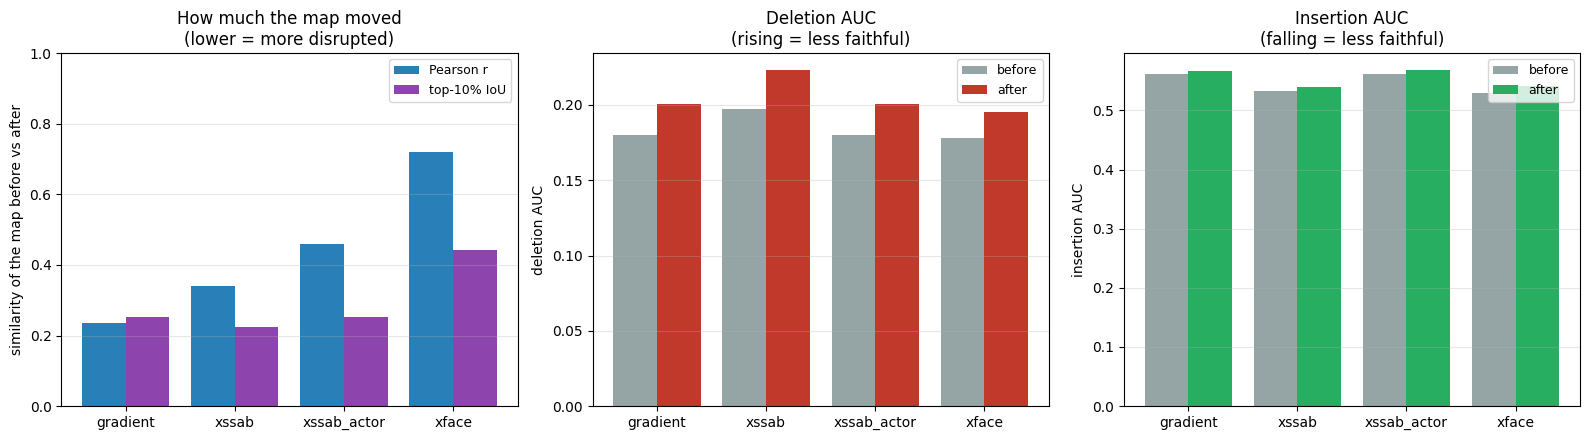

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
x = np.arange(len(TRANSFER_METHODS))

ax = axes[0]
ax.bar(x - 0.2, sdf.pearson, 0.4, label="Pearson r", color="#2980b9")
ax.bar(x + 0.2, sdf.topk_iou, 0.4, label="top-10% IoU", color="#8e44ad")
ax.set_xticks(x); ax.set_xticklabels(TRANSFER_METHODS)
ax.set_ylim(0, 1); ax.set_ylabel("similarity of the map before vs after")
ax.set_title("How much the map moved\n(lower = more disrupted)")
ax.legend(fontsize=9); ax.grid(alpha=0.3, axis="y")

ax = axes[1]
ax.bar(x - 0.2, sdf.del_auc_before, 0.4, label="before", color="#95a5a6")
ax.bar(x + 0.2, sdf.del_auc_after, 0.4, label="after", color="#c0392b")
ax.set_xticks(x); ax.set_xticklabels(TRANSFER_METHODS)
ax.set_ylabel("deletion AUC"); ax.set_title("Deletion AUC\n(rising = less faithful)")
ax.legend(fontsize=9); ax.grid(alpha=0.3, axis="y")

ax = axes[2]
ax.bar(x - 0.2, sdf.ins_auc_before, 0.4, label="before", color="#95a5a6")
ax.bar(x + 0.2, sdf.ins_auc_after, 0.4, label="after", color="#27ae60")
ax.set_xticks(x); ax.set_xticklabels(TRANSFER_METHODS)
ax.set_ylabel("insertion AUC"); ax.set_title("Insertion AUC\n(falling = less faithful)")
ax.legend(fontsize=9); ax.grid(alpha=0.3, axis="y")

plt.tight_layout(); save_fig("09_transfer_summary.png"); plt.show()

## Mean insertion and deletion curves, before vs after

The picture behind the AUC table. For each method the solid pair is the unattacked
explanation and the dashed pair is the attacked one. A successful attack pulls the
deletion curve **up** (deleting the highlighted pixels no longer destroys the match) and
the insertion curve **down** (restoring them no longer rebuilds it).

saved /kaggle/working/09_insdel_before_after.png


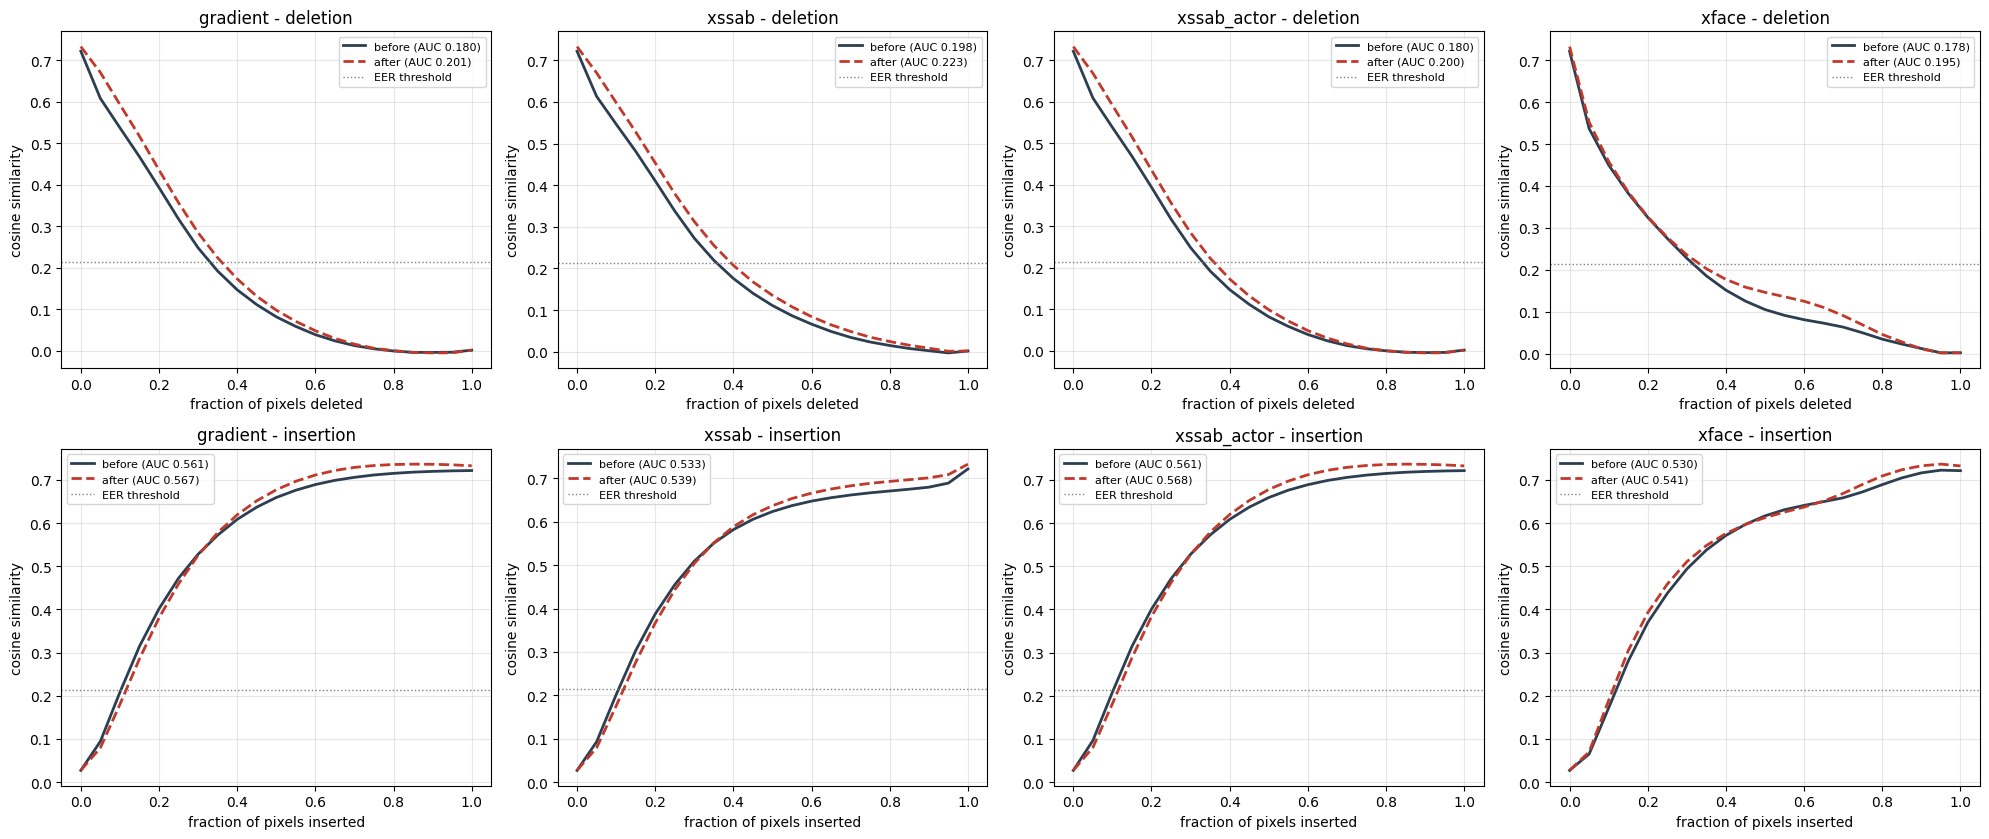

In [16]:
xs = np.linspace(0, 1, INSDEL_STEPS + 1)
fig, axes = plt.subplots(2, len(TRANSFER_METHODS),
                         figsize=(5 * len(TRANSFER_METHODS), 8.5), squeeze=False)
for c, m in enumerate(TRANSFER_METHODS):
    for r, kind in enumerate(["del", "ins"]):
        ax = axes[r][c]
        before = curve_store[m][f"{kind}_before"].mean(0)
        after = curve_store[m][f"{kind}_after"].mean(0)
        ax.plot(xs, before, lw=2, color="#2c3e50",
                label=f"before (AUC {curve_auc(before):.3f})")
        ax.plot(xs, after, lw=2, ls="--", color="#c0392b",
                label=f"after (AUC {curve_auc(after):.3f})")
        ax.axhline(TAU_EER, color="grey", ls=":", lw=1, label="EER threshold")
        ax.set_xlabel("fraction of pixels " + ("deleted" if kind == "del" else "inserted"))
        ax.set_ylabel("cosine similarity")
        ax.set_title(f"{m} - {'deletion' if kind == 'del' else 'insertion'}")
        ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); save_fig("09_insdel_before_after.png"); plt.show()

saved /kaggle/working/09_metric_distributions.png


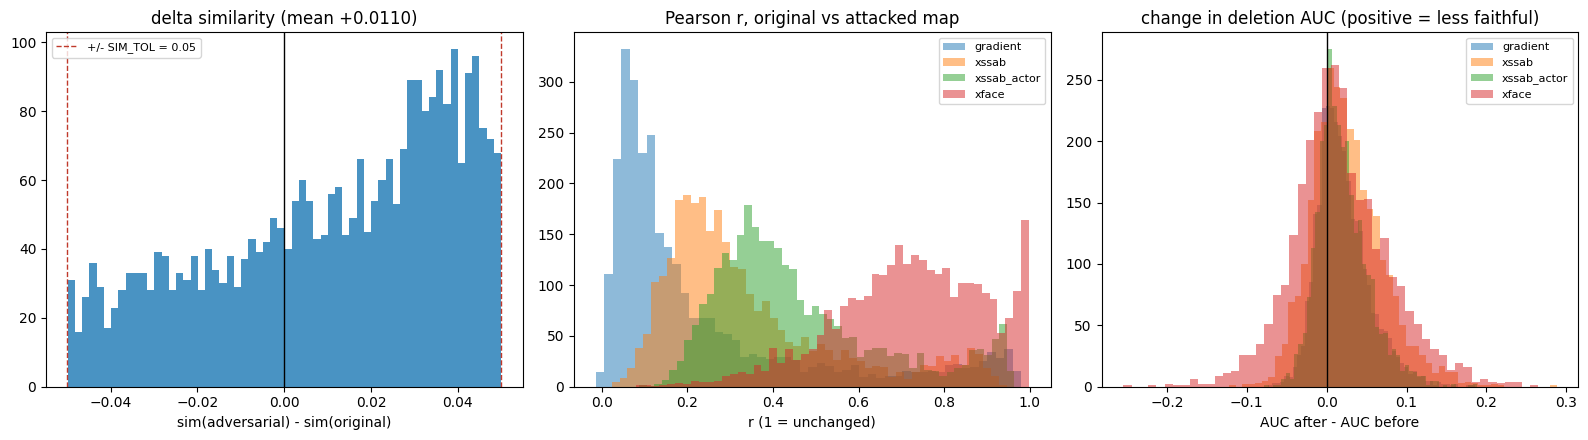

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].hist(edf.delta_sim, bins=60, color="#2980b9", alpha=0.85)
axes[0].axvline(0, color="k", lw=1)
axes[0].axvline(SIM_TOL, color="#c0392b", ls="--", lw=1, label=f"+/- SIM_TOL = {SIM_TOL}")
axes[0].axvline(-SIM_TOL, color="#c0392b", ls="--", lw=1)
axes[0].set_title(f"delta similarity (mean {edf.delta_sim.mean():+.4f})")
axes[0].set_xlabel("sim(adversarial) - sim(original)"); axes[0].legend(fontsize=8)

method_colors = plt.cm.tab10(np.linspace(0, 1, 10))[:len(TRANSFER_METHODS)]
for m, col in zip(TRANSFER_METHODS, method_colors):
    axes[1].hist(edf[f"{m}_pearson"], bins=50, alpha=0.5, label=m, color=col)
axes[1].set_title("Pearson r, original vs attacked map")
axes[1].set_xlabel("r (1 = unchanged)"); axes[1].legend(fontsize=8)

for m, col in zip(TRANSFER_METHODS, method_colors):
    axes[2].hist(edf[f"{m}_del_auc_after"] - edf[f"{m}_del_auc_before"],
                 bins=50, alpha=0.5, label=m, color=col)
axes[2].axvline(0, color="k", lw=1)
axes[2].set_title("change in deletion AUC (positive = less faithful)")
axes[2].set_xlabel("AUC after - AUC before"); axes[2].legend(fontsize=8)

plt.tight_layout(); save_fig("09_metric_distributions.png"); plt.show()

## Qualitative examples

Top row: the original probe and its explanations. Bottom row: the adversarial probe and
its explanations. The two photographs should be indistinguishable to your eye and the
similarity should barely move, while the heatmaps shift.

saved /kaggle/working/09_example_pair0.png


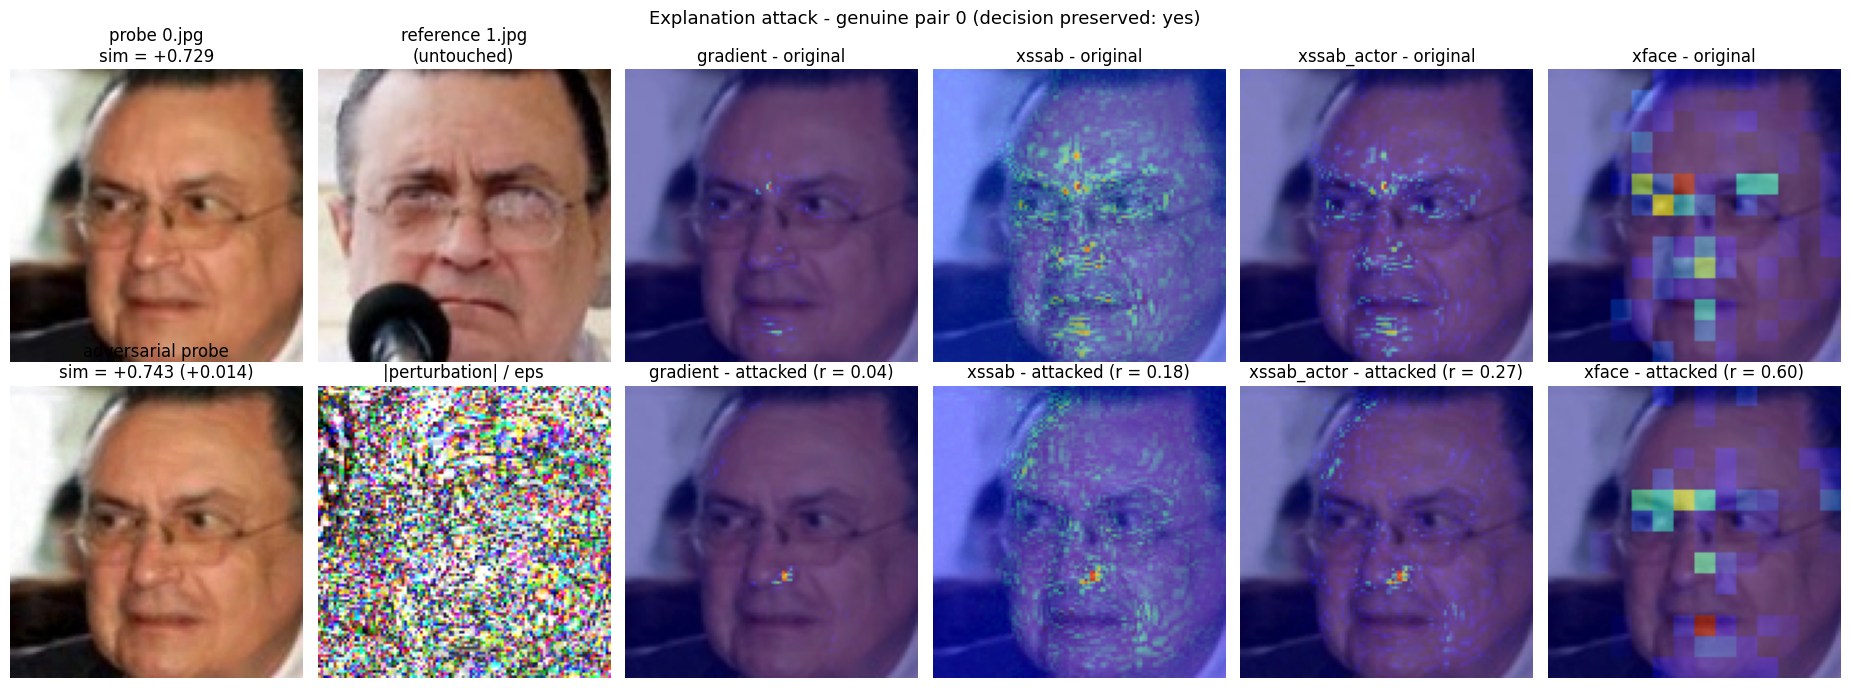

saved /kaggle/working/09_example_pair1.png


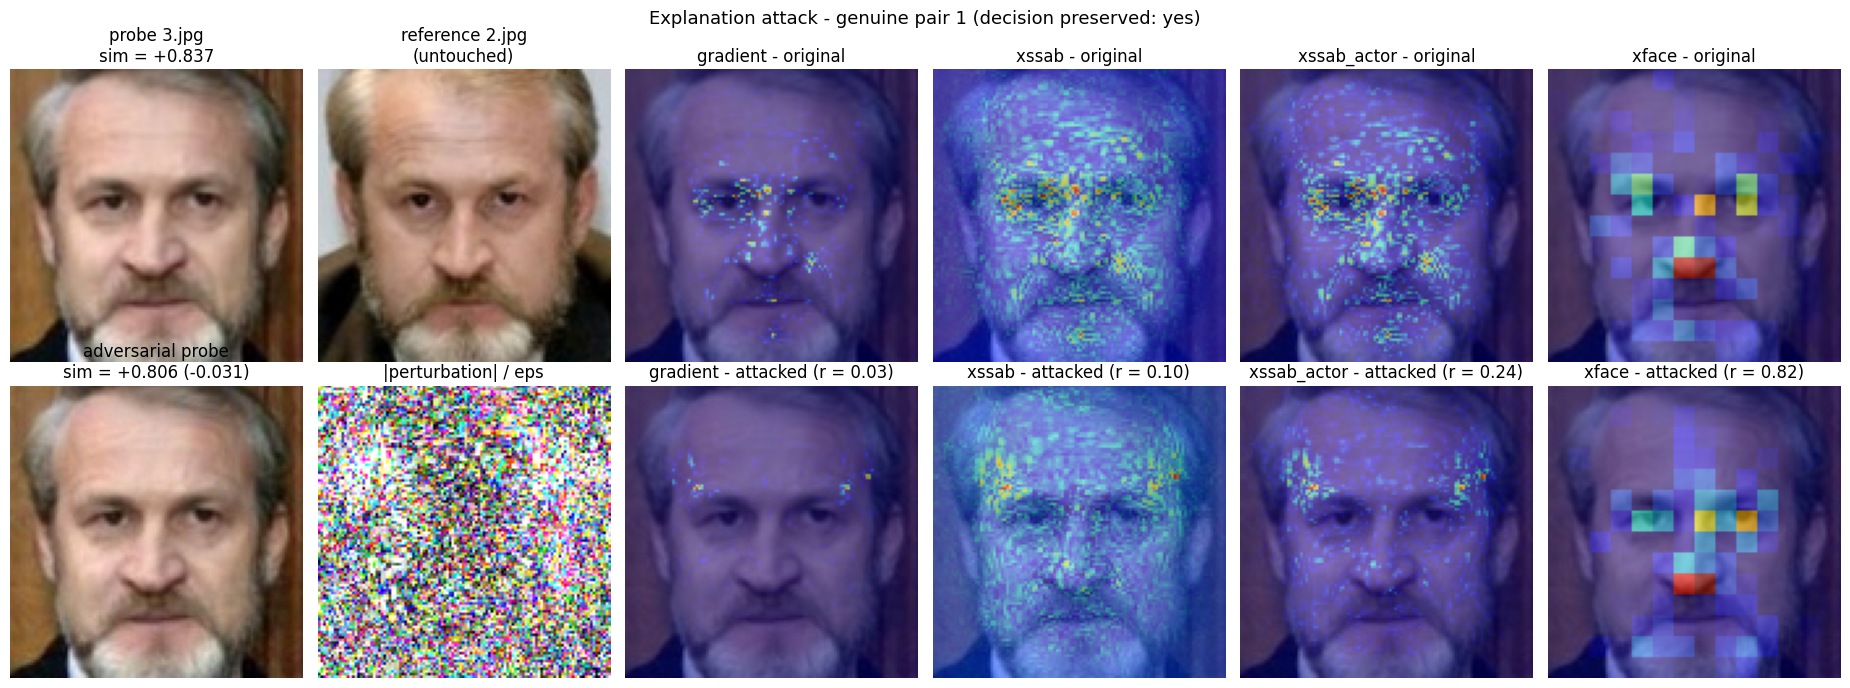

saved /kaggle/working/09_example_pair3000.png


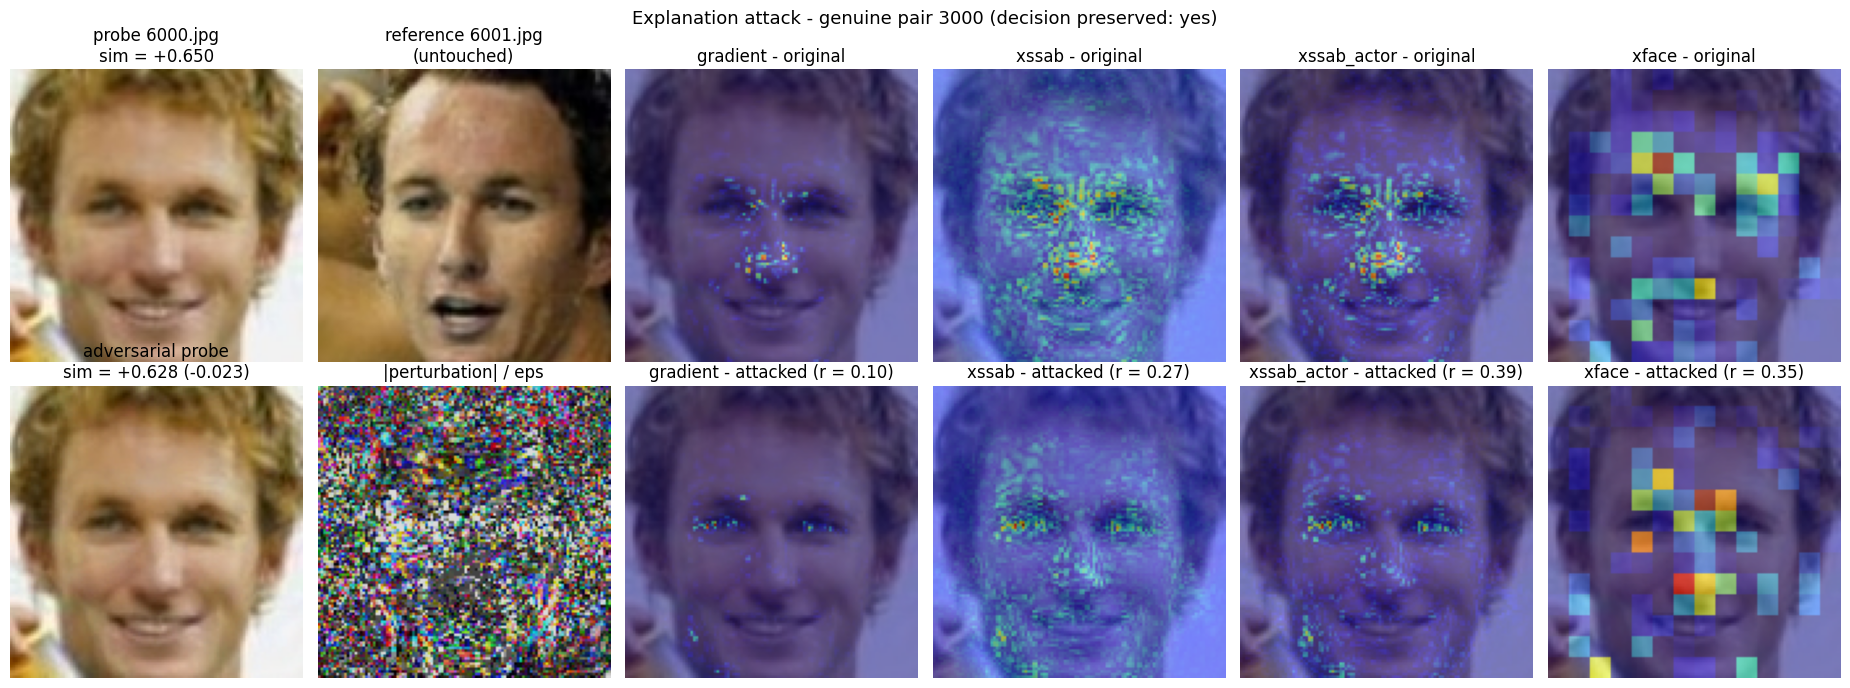

In [18]:
def visualise(pair_idx):
    probes, refs = load_pair_batch([pair_idx])
    ref_emb = ref_embedding(refs)
    adv = explanation_attack(probes, ref_emb, TAU_EER)
    s0 = float(cos_to_ref(probes, ref_emb))
    s1 = float(cos_to_ref(adv, ref_emb))
    pr, rf = probe_reference(pair_idx)

    n = len(TRANSFER_METHODS)
    fig, ax = plt.subplots(2, n + 2, figsize=(3.1 * (n + 2), 7))

    ax[0, 0].imshow(tensor_to_uint8(probes[0]))
    ax[0, 0].set_title(f"probe {pr}.jpg\nsim = {s0:+.3f}")
    ax[1, 0].imshow(tensor_to_uint8(adv[0]))
    ax[1, 0].set_title(f"adversarial probe\nsim = {s1:+.3f} ({s1 - s0:+.3f})")

    ax[0, 1].imshow(tensor_to_uint8(refs[0]))
    ax[0, 1].set_title(f"reference {rf}.jpg\n(untouched)")
    pert = ((adv - probes).abs() / (EPSILON_255 / 127.5)).clamp(0, 1)
    ax[1, 1].imshow((pert[0].permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8))
    ax[1, 1].set_title("|perturbation| / eps")

    for k, m in enumerate(TRANSFER_METHODS):
        mb = compute_saliency(m, probes, ref_emb, [pair_idx])[0].cpu().numpy()
        ma = compute_saliency(m, adv, ref_emb, [pair_idx])[0].cpu().numpy()
        r = float(pearson_maps(mb[None], ma[None])[0])
        ax[0, 2 + k].imshow(overlay(probes[0], to01(mb)))
        ax[0, 2 + k].set_title(f"{m} - original")
        ax[1, 2 + k].imshow(overlay(adv[0], to01(ma)))
        ax[1, 2 + k].set_title(f"{m} - attacked (r = {r:.2f})")

    for a in ax.flatten():
        a.axis("off")
    fig.suptitle(f"Explanation attack - genuine pair {pair_idx} "
                 f"(decision preserved: {'yes' if (s0 >= TAU_EER) == (s1 >= TAU_EER) else 'NO'})",
                 fontsize=13)
    plt.tight_layout()
    save_fig(f"09_example_pair{pair_idx}.png")
    plt.show()


for p in VIZ_PAIRS:
    if p in set(accepted_genuine.tolist()):
        visualise(p)

## Save

In [19]:
np.savez_compressed(
    os.path.join(OUTPUT_DIR, "explanation_attack_curves.npz"),
    x=xs, pairs=pairs,
    **{f"{m}_{k}_mean": curve_store[m][k].mean(0)
       for m in TRANSFER_METHODS
       for k in ("del_before", "ins_before", "del_after", "ins_after")},
    **{f"{m}_{k}_all": curve_store[m][k]
       for m in TRANSFER_METHODS
       for k in ("del_before", "ins_before", "del_after", "ins_after")},
)
with open(os.path.join(OUTPUT_DIR, "explanation_attack_config.json"), "w") as fh:
    json.dump(dict(epsilon_255=EPSILON_255, steps=STEPS_EXPL, alpha_frac=ALPHA_FRAC,
                   lambda_pred=LAMBDA_PRED, lambda_expl=LAMBDA_EXPL, sim_tol=SIM_TOL,
                   attacked_method=ATTACKED_METHOD, transfer_methods=TRANSFER_METHODS,
                   insdel_steps=INSDEL_STEPS, eer_threshold=TAU_EER, eer=EER,
                   n_pairs=int(len(pairs)), thresholds=THRESHOLDS), fh, indent=2)
print("saved explanation_attack.csv, explanation_attack_summary.csv, "
      "explanation_attack_curves.npz, explanation_attack_config.json")

saved explanation_attack.csv, explanation_attack_summary.csv, explanation_attack_curves.npz, explanation_attack_config.json


## Results and discussion

### 1. The decision is untouched - this half is an unambiguous success

Across 2,991 accepted genuine pairs the mean score change is **+0.011**, the mean absolute
change **0.026**, and 95% of pairs move by less than 0.047 - inside the +/-0.05 band by
construction. The decision is preserved on **100% of pairs at every operating point**
tested (EER, and FMR = 10^-1, 10^-2, 10^-3), not merely at the threshold the attack was
tuned against. The hard projection engaged gently - 0.31 halvings per sample-step and the
cap was never hit - so the constraint shaped the attack without strangling it.

This is a strictly stronger claim than notebook 04 could make. There, a one-sided floor let
a genuine pair drift from 0.73 to 0.82; here the score stays where it was.

### 2. The map changes a great deal

For the targeted gradient map, Pearson correlation with the original explanation falls to
**0.236 on average and 0.128 at the median**, and only 25% of the top-10% hot-spot pixels
survive. Visually and by any map-comparison metric, a reviewer would be shown a different
explanation.

### 3. But the map does not become substantially *wrong* - and that is the finding

This is what the insertion/deletion evaluation was built to detect, and it disagrees with
the correlation result:

| method | deletion AUC before -> after | distance travelled toward the random floor (0.370) |
|---|---|---|
| gradient (targeted) | 0.180 -> 0.201 | **10.9%** |
| xssab | 0.198 -> 0.223 | 14.9% |
| xssab_actor | 0.180 -> 0.200 | 10.8% |
| xface | 0.178 -> 0.195 | 9.1% |

The rise is overwhelmingly significant (paired t-test, p ~ 1e-221 at n = 2,991) but small:
the attacked explanation retains roughly **89% of its faithfulness**. Insertion barely
moves at all, and if anything drifts the wrong way (0.561 -> 0.567) - consistent with
notebook 07's finding that insertion has only 0.08 of headroom here and is a weak
discriminator.

**So the attack scrambles what the map looks like without substantially destroying what it
knows.** The mechanism is real but weak, and two pieces of evidence confirm it is a
mechanism rather than noise:

* Per pair, the amount the map moved predicts the faithfulness lost: correlation between
  Pearson r and the deletion-AUC rise is **-0.347** (p ~ 1e-85).
* On the 200 most-disrupted pairs (r <= 0.034), deletion AUC rises 0.225 -> 0.282 - nearly
  three times the average shift.

**Why this matters more than a clean success would have.** Notebooks 03-05 reported "map
correlation fell to 0.06, the attack works". With only a correlation metric, this run would
have been written up the same way, on r = 0.236. The insertion/deletion curves the
supervisor asked for are precisely what separates *"the explanation changed"* from *"the
explanation became wrong"* - and they show the first happened and the second largely did
not. That is a negative result for the strong claim and a positive result for the
methodology.

**The likely cause is an objective/metric mismatch - the same class of error notebook 03
made.** Notebook 03 optimised MSE between maps but reported correlation. This notebook
optimises *correlation* but evaluates *faithfulness*. Those are different quantities: a
face is highly redundant - eyes, nose bridge, mouth and jawline all carry identity - so the
attack can move the ranking onto a different subset of genuinely informative pixels and
lower the correlation without ever pointing at anything uninformative. To make a map
*unfaithful* the attack has to push its mass onto pixels that carry **no** identity
evidence, which decorrelation does not require it to do.

**A second contributing factor: the attack is budget-constrained.** Only 44.8% of pairs
reach the full 4/255 budget, and 49.9% are shrunk below 3/255 by the two-sided similarity
constraint (mean L-infinity 2.67/255). Holding the score to +/-0.05 costs real attack
strength - this is the price of the stronger "the score did not move" claim, and notebook
04's r = 0.06 was purchased by letting the score drift by +0.09 instead.

### 4. Transfer: a clean staircase

| explanation | Pearson r after attack | reading |
|---|---|---|
| gradient (the attacked map) | **0.236** | strongly disrupted - its own target |
| xssab (actor - counteractor) | 0.341 | substantially disrupted |
| xssab_actor | 0.458 | partially disrupted |
| xface (occlusion, gradient-free) | **0.720** | largely resisted |

The ordering rises monotonically with distance from what the attack optimised. The
gradient-free occlusion method retains most of its explanation, so **this is an attack on a
*family* of explanations - gradient-based ones - not on the model's reasoning as such.** An
auditor using an occlusion-based tool would still see roughly the truth. That is an honest,
reportable limitation, and it points directly at both the defence (audit with a method from
another family) and the next experiment (optimise against several maps at once).

### 5. Which xSSAB map to use - the notebook 07 ranking was an artefact

Notebook 07 ranked xSSAB last of the three methods, but it was scored on the *combined*
actor-minus-counteractor map. Measuring both variants here settles it:

| variant | deletion AUC | insertion AUC | faithfulness gap |
|---|---|---|---|
| xssab (combined) | 0.198 | 0.533 | 0.336 |
| **xssab_actor** | **0.180** | **0.561** | **0.381** |
| gradient | 0.180 | 0.561 | 0.381 |

**The actor map alone is as faithful as the raw input-gradient map, and clearly better than
the combined map.** xSSAB does not rank last; the combined map does. Notebook 07's ordering
should be read with that correction, and `xssab_actor` is the variant to quote.

### Limitations

* **The attack is only partially successful on its real objective.** It changes the
  explanation's appearance but leaves ~89% of its faithfulness intact. The headline should
  be phrased accordingly, not as "the explanation was destroyed".
* **White box.** Full gradient access is assumed; black-box and cross-model transfer are
  untested.
* **Digital only.** No JPEG re-compression, resizing or print-scan robustness. The
  perturbations are pixel-exact.
* **One dataset, one model** - LFW with ElasticFace-Arc, which is close to saturated.
* **xSSAB is our implementation**, from the WACV 2024 paper and the reference
  implementation's documented behaviour, not the official code (which carries no licence).
* **Insertion/deletion has a masking confound**, bounded but not eliminated by the random
  control in notebook 07.
* **Accepted genuine pairs only.** Attacking the dissimilarity explanation of a rejected
  pair - the counteractor side of xSSAB - is untouched.

### The clear next experiment

Attack faithfulness *directly* instead of correlation. The natural form is the `"target"`
objective: push saliency mass into the off-face border region, where pixels carry no
identity evidence, so that deleting the highlighted pixels genuinely fails to break the
match. If that moves the deletion AUC materially further toward the random floor, the pair
of results - decorrelation preserves faithfulness, targeting destroys it - is a
considerably stronger contribution than either alone.
